In [1]:
import torch, torchvision, sklearn
print(torch.__version__, torchvision.__version__)

2.14.1+cpu 0.29.1+cpu


In [2]:
from pathlib import Path
import json, random
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cpu"
DATA_DIR = Path("data/wikiart_subset")
IMAGE_SIZE = 64
BATCH_SIZE = 128

# 1. Load every image once into one tensor
ds = datasets.ImageFolder(DATA_DIR, transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()]))
CLASSES = ds.classes
X_all = torch.stack([img for img, _ in ds])   # (N, 3, 64, 64), pixels in [0, 1]
y_all = torch.tensor(ds.targets)               # (N,), int64
y_np = y_all.numpy()

# 2. Stratified split 70 / 15 / 15
idx = np.arange(len(y_np))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_np, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_np[tmp_idx], random_state=SEED)
train_idx, val_idx, test_idx = map(torch.from_numpy, (train_idx, val_idx, test_idx))

# 3. Standardise with the TRAINING mean and std only
mean = X_all[train_idx].mean().item()
std = X_all[train_idx].std().item()
X = (X_all - mean) / std

# 4. DataLoaders
train_loader = DataLoader(TensorDataset(X[train_idx], y_all[train_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X[val_idx],   y_all[val_idx]),   batch_size=1000)
test_loader  = DataLoader(TensorDataset(X[test_idx],  y_all[test_idx]),  batch_size=1000)

# Save the split so the group tests on the same images
Path("outputs").mkdir(exist_ok=True)
Path("outputs/split.json").write_text(json.dumps(
    {"train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist()}))

print("classes:", CLASSES)
print(f"mean {mean:.4f}, std {std:.4f}")
for name, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s} {len(ids):4d} | per class {np.bincount(y_np[ids.numpy()])}")

classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
mean 0.4921, std 0.2608
train  350 | per class [70 70 70 70 70]
val     75 | per class [15 15 15 15 15]
test    75 | per class [15 15 15 15 15]


In [3]:
from torchvision.models import resnet18, ResNet18_Weights
import time

# Pretrained ResNet-18, last layer removed: it now outputs 512 features per image
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # downloads ~45 MB the first time
backbone.fc = nn.Identity()
backbone.eval()
for p in backbone.parameters():
    p.requires_grad = False   # frozen: no weight of the backbone is trained

# ResNet expects 224x224 images normalised with the ImageNet mean/std (not our own standardisation)
resnet_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
ds_r = datasets.ImageFolder(DATA_DIR, transform=resnet_tf)
assert ds_r.targets == ds.targets, "same image order as cell 1, so split.json still applies"

# Extract the features once
feats = []
t0 = time.perf_counter()
with torch.no_grad():
    for xb, _ in DataLoader(ds_r, batch_size=32):
        feats.append(backbone(xb))
elapsed = time.perf_counter() - t0
F_all = torch.cat(feats)   # (500, 512)

print("features:", tuple(F_all.shape))
print(f"CPU time: {1000 * elapsed / len(F_all):.1f} ms per image (batches of 32)")

features: (500, 512)
CPU time: 10.0 ms per image (batches of 32)


In [4]:
# Course helpers (TP04/TP05): training loop and evaluation

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history

epoch  1 | train loss 1.6053 | val loss 1.3763 | val acc 0.413
epoch  2 | train loss 1.2250 | val loss 1.1527 | val acc 0.627
epoch  3 | train loss 1.0014 | val loss 0.9633 | val acc 0.720
epoch  4 | train loss 0.8410 | val loss 0.8722 | val acc 0.773
epoch  5 | train loss 0.7318 | val loss 0.7978 | val acc 0.800
epoch  6 | train loss 0.6677 | val loss 0.7629 | val acc 0.787
epoch  7 | train loss 0.5837 | val loss 0.7188 | val acc 0.800
epoch  8 | train loss 0.5310 | val loss 0.6902 | val acc 0.813
epoch  9 | train loss 0.4847 | val loss 0.6814 | val acc 0.813
epoch 10 | train loss 0.4529 | val loss 0.6551 | val acc 0.827
epoch 11 | train loss 0.4240 | val loss 0.6457 | val acc 0.853
epoch 12 | train loss 0.3961 | val loss 0.6270 | val acc 0.840
epoch 13 | train loss 0.3719 | val loss 0.6286 | val acc 0.827
epoch 14 | train loss 0.3497 | val loss 0.6104 | val acc 0.853
epoch 15 | train loss 0.3362 | val loss 0.6032 | val acc 0.827
epoch 16 | train loss 0.3167 | val loss 0.5988 | val ac

epoch 29 | train loss 0.1832 | val loss 0.5670 | val acc 0.827
epoch 30 | train loss 0.1726 | val loss 0.5744 | val acc 0.827


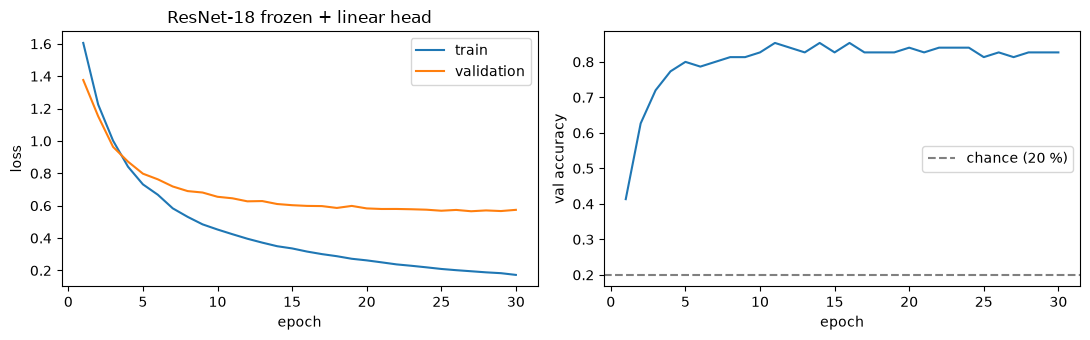

In [5]:
torch.manual_seed(SEED)
F_train, F_val, F_test = F_all[train_idx], F_all[val_idx], F_all[test_idx]
y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]

ftrain_loader = DataLoader(TensorDataset(F_train, y_train), batch_size=32, shuffle=True)
fval_loader   = DataLoader(TensorDataset(F_val, y_val), batch_size=1000)
ftest_loader  = DataLoader(TensorDataset(F_test, y_test), batch_size=1000)   # used once, at the very end

head = nn.Linear(512, len(CLASSES))   # 512 * 5 + 5 = 2565 trainable parameters
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
history_head = fit(head, ftrain_loader, fval_loader, loss_fn, optimizer, n_epochs=30)

# Training curves
epochs = range(1, len(history_head["train_loss"]) + 1)
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_head["train_loss"], label="train")
plt.plot(epochs, history_head["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("ResNet-18 frozen + linear head")
plt.subplot(1, 2, 2)
plt.plot(epochs, history_head["val_acc"])
plt.axhline(1 / len(CLASSES), ls="--", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend()
plt.tight_layout(); plt.show()

## Step 1 — Classical baselines (validation only)

Is a neural network worth it on a CPU kiosk? We compare with **logistic regression**, a classical linear model, on the same split:

- **Raw pixels**: the standardised 64×64 images, flattened. No knowledge of what images look like.
- **ResNet features**: the 512 frozen ResNet-18 features from cell 2. Same input as the linear head.

The regularisation strength `C` is chosen on the **validation set**. The test set is not used here.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

C_GRID = [0.001, 0.01, 0.1, 1, 10]   # C = inverse of regularisation strength: small C = simpler model


def pick_C(X_tr, y_tr, X_va, y_va, name):
    # Fit one logistic regression per C and keep the best on validation (ties -> smaller C)
    best = None
    for C in C_GRID:
        clf = LogisticRegression(C=C, max_iter=5000)
        clf.fit(X_tr, y_tr)
        tr_acc, va_acc = clf.score(X_tr, y_tr), clf.score(X_va, y_va)
        print(f"{name} | C={C:<6} | train acc {tr_acc:.3f} | val acc {va_acc:.3f}")
        if best is None or va_acc > best["val_acc"]:
            best = {"C": C, "model": clf, "train_acc": tr_acc, "val_acc": va_acc}
    print(f"-> chosen C={best['C']} | val acc {best['val_acc']:.3f}\n")
    return best


# 1. Raw pixels: each standardised image (cell 1) flattened into 3 * 64 * 64 = 12288 numbers
P_train, P_val = X[train_idx].flatten(1).numpy(), X[val_idx].flatten(1).numpy()
logreg_pixels = pick_C(P_train, y_train.numpy(), P_val, y_val.numpy(), "LogReg raw pixels    ")

# 2. ResNet features: standardise each of the 512 features with the TRAINING mean/std only
scaler = StandardScaler().fit(F_train.numpy())
S_train, S_val = scaler.transform(F_train.numpy()), scaler.transform(F_val.numpy())
logreg_feats = pick_C(S_train, y_train.numpy(), S_val, y_val.numpy(), "LogReg ResNet features")

LogReg raw pixels     | C=0.001  | train acc 0.920 | val acc 0.293


LogReg raw pixels     | C=0.01   | train acc 1.000 | val acc 0.307


LogReg raw pixels     | C=0.1    | train acc 1.000 | val acc 0.347


LogReg raw pixels     | C=1      | train acc 1.000 | val acc 0.320


LogReg raw pixels     | C=10     | train acc 1.000 | val acc 0.360
-> chosen C=10 | val acc 0.360

LogReg ResNet features | C=0.001  | train acc 0.920 | val acc 0.827
LogReg ResNet features | C=0.01   | train acc 0.977 | val acc 0.840
LogReg ResNet features | C=0.1    | train acc 1.000 | val acc 0.813
LogReg ResNet features | C=1      | train acc 1.000 | val acc 0.800
LogReg ResNet features | C=10     | train acc 1.000 | val acc 0.813
-> chosen C=0.01 | val acc 0.840



In [7]:
# Validation summary so far (75 validation images: 1 image = 1.3 percentage points)
n_val = len(val_idx)
val_results = {
    "LogReg on raw pixels": logreg_pixels["val_acc"],
    "LogReg on ResNet-18 features": logreg_feats["val_acc"],
    "ResNet-18 frozen + linear head (epoch 30)": history_head["val_acc"][-1],
}
print(f"{'chance':45s} val acc {1 / len(CLASSES):.3f}")
for name, acc in val_results.items():
    print(f"{name:45s} val acc {acc:.3f}  ({round(acc * n_val)}/{n_val} images)")

chance                                        val acc 0.200
LogReg on raw pixels                          val acc 0.360  (27/75 images)
LogReg on ResNet-18 features                  val acc 0.840  (63/75 images)
ResNet-18 frozen + linear head (epoch 30)     val acc 0.827  (62/75 images)


## Step 2 — Fine-tune the last ResNet block (validation only)

Frozen version: only the linear head learns (2,565 weights). Here we also retrain **`layer4`**, the last block of ResNet-18, so the features themselves can adapt to painting styles.

- Blocks 1–3 stay frozen, so their output is computed **once** and cached; only `layer4` + a new head are trained, with the course `fit` helper.
- Learning rate 1e-4 for the pretrained block (small steps, so we don't destroy what it learned on ImageNet) and 1e-3 for the new head (same as the frozen version).
- The weights from the epoch with the best validation accuracy are kept. The test set is not used.

In [8]:
import copy

# Blocks 1-3 are frozen and in eval mode, so their output never changes: compute it once for all 500 images
def frozen_trunk(x):
    b = backbone
    x = b.maxpool(b.relu(b.bn1(b.conv1(x))))
    return b.layer3(b.layer2(b.layer1(x)))

with torch.no_grad():
    H_all = torch.cat([frozen_trunk(xb) for xb, _ in DataLoader(ds_r, batch_size=32)])   # (500, 256, 14, 14)

    # Sanity check: frozen layer4 + average pooling on the cache must give back the features of cell 2
    F_check = backbone.avgpool(backbone.layer4(H_all[:16])).flatten(1)
    assert torch.allclose(F_check, F_all[:16], atol=1e-4)

print("cached layer3 output:", tuple(H_all.shape))

cached layer3 output: (500, 256, 14, 14)


trainable parameters: 8,396,293 (frozen version: 2,565)


epoch  1 | train loss 1.2143 | val loss 0.8866 | val acc 0.653


epoch  2 | train loss 0.3291 | val loss 0.5569 | val acc 0.827


epoch  3 | train loss 0.1310 | val loss 0.5542 | val acc 0.827


epoch  4 | train loss 0.0410 | val loss 0.5070 | val acc 0.827


...

epoch 11 | train loss 0.0056 | val loss 0.5097 | val acc 0.840


epoch 12 | train loss 0.0032 | val loss 0.5068 | val acc 0.840


epoch 13 | train loss 0.0035 | val loss 0.5183 | val acc 0.840


epoch 14 | train loss 0.0026 | val loss 0.5175 | val acc 0.840


epoch 15 | train loss 0.0031 | val loss 0.5189 | val acc 0.840

best epoch 6 (val acc 0.853) | training time 28 s on CPU


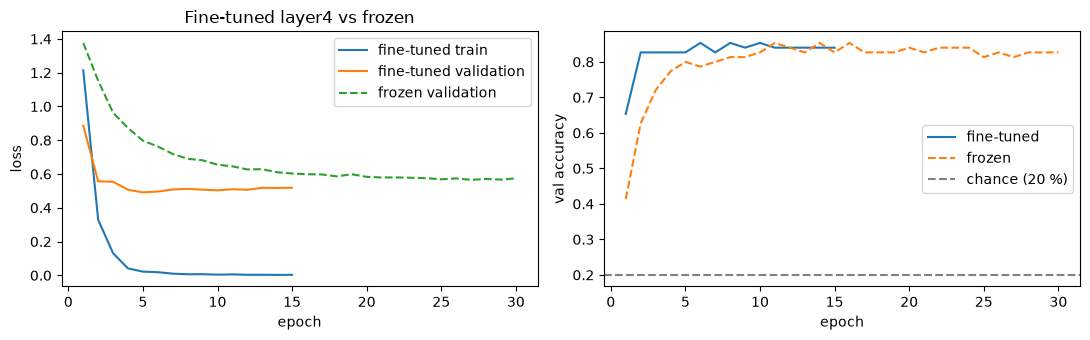

In [9]:
torch.manual_seed(SEED)

# Trainable part: a COPY of layer4 (the frozen backbone stays untouched) + a new linear head
finetuned = nn.Sequential(
    copy.deepcopy(backbone.layer4),
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(512, len(CLASSES)),
)
for p in finetuned.parameters():
    p.requires_grad = True
n_params_ft = sum(p.numel() for p in finetuned.parameters())
print(f"trainable parameters: {n_params_ft:,} (frozen version: {sum(p.numel() for p in head.parameters()):,})")

htrain_loader = DataLoader(TensorDataset(H_all[train_idx], y_train), batch_size=32, shuffle=True)
hval_loader   = DataLoader(TensorDataset(H_all[val_idx], y_val), batch_size=1000)

optimizer_ft = torch.optim.Adam([
    {"params": finetuned[0].parameters(), "lr": 1e-4},   # pretrained block: small steps
    {"params": finetuned[3].parameters(), "lr": 1e-3},   # new head: same lr as the frozen version
])

# Train one epoch at a time with the course fit helper, keeping the best weights on validation
N_EPOCHS_FT = 15
history_ft = {"train_loss": [], "val_loss": [], "val_acc": []}
best_val_acc, best_epoch, best_state = -1.0, None, None
t0 = time.perf_counter()
for epoch in range(1, N_EPOCHS_FT + 1):
    h = fit(finetuned, htrain_loader, hval_loader, loss_fn, optimizer_ft, n_epochs=1, verbose=False)
    for k in history_ft:
        history_ft[k] += h[k]
    print(f"epoch {epoch:2d} | train loss {h['train_loss'][0]:.4f} | val loss {h['val_loss'][0]:.4f} | val acc {h['val_acc'][0]:.3f}")
    if h["val_acc"][0] > best_val_acc:
        best_val_acc, best_epoch = h["val_acc"][0], epoch
        best_state = copy.deepcopy(finetuned.state_dict())
train_time_ft = time.perf_counter() - t0
finetuned.load_state_dict(best_state)
print(f"\nbest epoch {best_epoch} (val acc {best_val_acc:.3f}) | training time {train_time_ft:.0f} s on CPU")

# Training curves: frozen vs fine-tuned
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["train_loss"], label="fine-tuned train")
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["val_loss"], label="fine-tuned validation")
plt.plot(epochs, history_head["val_loss"], ls="--", label="frozen validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("Fine-tuned layer4 vs frozen")
plt.subplot(1, 2, 2)
plt.plot(range(1, N_EPOCHS_FT + 1), history_ft["val_acc"], label="fine-tuned")
plt.plot(epochs, history_head["val_acc"], ls="--", label="frozen")
plt.axhline(1 / len(CLASSES), ls="--", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend()
plt.tight_layout(); plt.show()

In [10]:
# Frozen vs fine-tuned on the same validation images
# "best" = best epoch chosen on validation (slightly optimistic); "last" = final epoch
train_acc_head = evaluate(head, DataLoader(TensorDataset(F_train, y_train), batch_size=1000), loss_fn)[1]
train_acc_ft = evaluate(finetuned, DataLoader(TensorDataset(H_all[train_idx], y_train), batch_size=1000), loss_fn)[1]
rows = [
    ("ResNet-18 frozen + linear head", sum(p.numel() for p in head.parameters()), train_acc_head, history_head),
    ("ResNet-18 layer4 fine-tuned + head", n_params_ft, train_acc_ft, history_ft),
]
print(f"{'model':36s} {'trainable':>10s} {'train acc':>9s} {'val acc last':>12s} {'val acc best (epoch)':>21s}")
for name, n_p, tr_acc, hist in rows:
    best = max(hist["val_acc"])
    print(f"{name:36s} {n_p:>10,} {tr_acc:>9.3f} {hist['val_acc'][-1]:>12.3f} "
          f"{best:>13.3f} ({hist['val_acc'].index(best) + 1:2d})")
print("\n(train acc: frozen head at its last epoch, fine-tuned model at its kept best epoch)")

model                                 trainable train acc val acc last  val acc best (epoch)
ResNet-18 frozen + linear head            2,565     0.980        0.827         0.853 (11)
ResNet-18 layer4 fine-tuned + head    8,396,293     1.000        0.840         0.853 ( 6)

(train acc: frozen head at its last epoch, fine-tuned model at its kept best epoch)
